# 06 · (Optional extension) Late-delivery prediction prototype
**Goal:** can we flag, *at purchase time*, orders likely to be delivered late?

Design choices that avoid common mistakes:
- **Target:** `is_late` for delivered orders, purchases 2017-01 → 2018-08.
- **No leakage:** only features known at checkout (price, freight, weight/size, route, estimated delivery window, purchase time). *No* shipping dates, delivery days or review score.
- **Time-aware split:** train on purchases before Mar-2018, test on Mar–Aug 2018 (never shuffled).
- **Baselines:** majority class and logistic regression, before gradient boosting.
- **Metrics:** ROC-AUC and PR-AUC (late is rare → accuracy is meaningless).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, RocCurveDisplay
t = olist.load_raw(["items","products","sellers","translation"])

In [2]:
f = pd.read_csv(olist.PROCESSED / "order_facts.csv.gz", parse_dates=olist.ORDER_DATE_COLS)
prod = olist.category_table(t).set_index("product_id")
it = t["items"].merge(prod[["category","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]], left_on="product_id", right_index=True, how="left")
it["vol"] = it.product_length_cm * it.product_height_cm * it.product_width_cm
first = it.sort_values("order_item_id").drop_duplicates("order_id").set_index("order_id")
agg = it.groupby("order_id").agg(weight_g=("product_weight_g","sum"), volume_cm3=("vol","sum"))
first["seller_state"] = first.seller_id.map(t["sellers"].set_index("seller_id").seller_state)
X = f[f.is_delivered].set_index("order_id").join(agg).join(first[["category","seller_state"]])
X = X[(X.order_purchase_timestamp >= olist.TREND_START) & (X.order_purchase_timestamp < olist.TREND_END)].copy()
X["est_days"] = (X.order_estimated_delivery_date - X.order_purchase_timestamp).dt.total_seconds()/86400
X["same_state"] = (X.customer_state == X.seller_state).astype(int)
X["hour"] = X.order_purchase_timestamp.dt.hour; X["dow"] = X.order_purchase_timestamp.dt.dayofweek
X["y"] = X.is_late.astype(int)
num = ["item_revenue","freight","n_items","n_sellers","weight_g","volume_cm3","est_days","same_state","hour","dow","max_installments"]
cat = ["customer_state","seller_state","category","main_payment_type"]
top_cats = X.category.value_counts().head(25).index; X["category"] = X.category.where(X.category.isin(top_cats), "other")
X[cat] = X[cat].fillna("unknown"); X = X.dropna(subset=["est_days"])
split = pd.Timestamp("2018-03-01")
tr, te = X[X.order_purchase_timestamp < split], X[X.order_purchase_timestamp >= split]
print(f"train {len(tr):,} (late {tr.y.mean():.1%}) | test {len(te):,} (late {te.y.mean():.1%})")

train 57,050 (late 7.7%) | test 39,153 (late 8.8%)


In [3]:
def pipe(model, scale):
    pre = ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num), ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), cat)])
    return make_pipeline(pre, model)
models = {
    "Majority baseline": pipe(DummyClassifier(strategy="prior"), False),
    "Logistic regression": pipe(LogisticRegression(max_iter=1000, class_weight="balanced"), True),
    "HistGradientBoosting": pipe(HistGradientBoostingClassifier(max_depth=5, learning_rate=.06, max_iter=300, random_state=0), False),
}
rows, probs = {}, {}
for n, m in models.items():
    m.fit(tr[num+cat], tr.y); p = m.predict_proba(te[num+cat])[:, 1]; probs[n] = p
    rows[n] = {"ROC-AUC": roc_auc_score(te.y, p), "PR-AUC": average_precision_score(te.y, p)}
res = pd.DataFrame(rows).T; res["PR-AUC no-skill (= prevalence)"] = te.y.mean(); res

,ROC-AUC,PR-AUC,PR-AUC no-skill (= prevalence)
Majority baseline,0.50,0.09,0.09
Logistic regression,0.70,0.17,0.09
HistGradientBoosting,0.69,0.17,0.09


Flagging the riskiest 10% of orders catches 23.6% of all late orders (precision 20.7% vs base rate 8.8%; lift 2.4x)


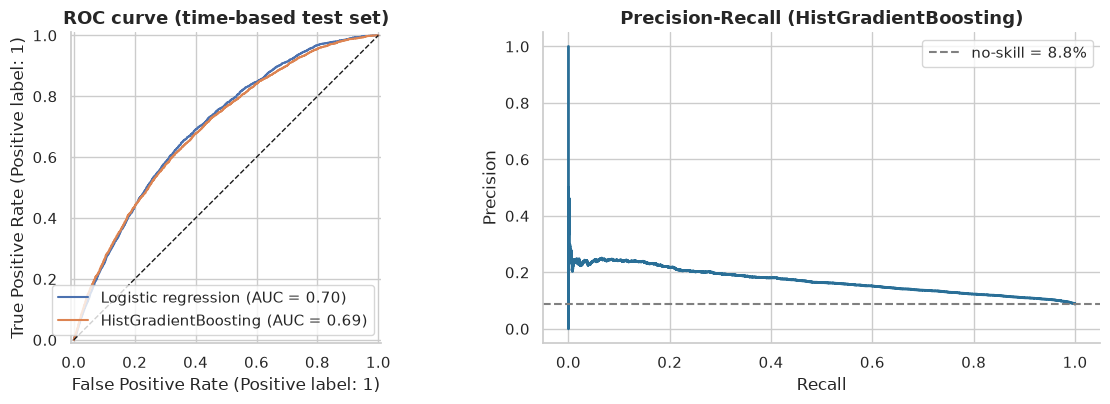

In [4]:
best = "HistGradientBoosting"; p = probs[best]
prec, rec, thr = precision_recall_curve(te.y, p)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for n in ["Logistic regression", best]:
    RocCurveDisplay.from_predictions(te.y, probs[n], name=n, ax=axes[0])
axes[0].plot([0,1],[0,1], "k--", lw=1); axes[0].set_title("ROC curve (time-based test set)")
axes[1].plot(rec, prec, color="#2a6f97", lw=2); axes[1].axhline(te.y.mean(), color="gray", ls="--", label=f"no-skill = {te.y.mean():.1%}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title(f"Precision-Recall ({best})"); axes[1].legend()
plt.tight_layout(); olist.save_fig(fig, "18_ml_roc_pr.png")
k = int(len(te)*.10); top = np.argsort(-p)[:k]
print(f"Flagging the riskiest 10% of orders catches {te.y.values[top].sum()/te.y.sum():.1%} of all late orders (precision {te.y.values[top].mean():.1%} vs base rate {te.y.mean():.1%}; lift {te.y.values[top].mean()/te.y.mean():.1f}x)")

est_days         0.05
customer_state   0.04
freight          0.01
same_state       0.01
seller_state     0.00
n_items          0.00
dtype: float64

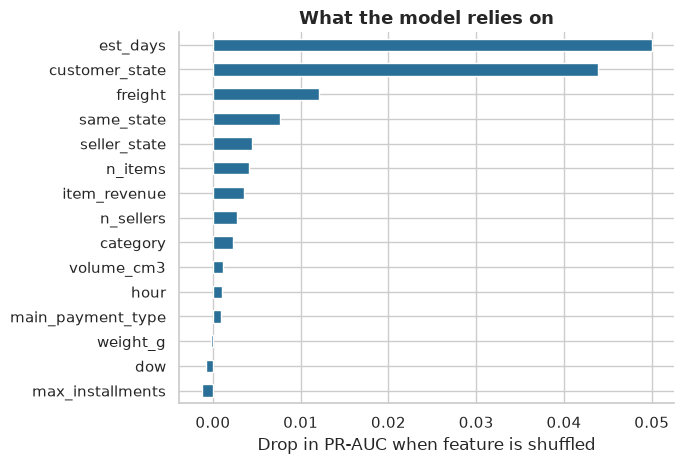

In [5]:
from sklearn.inspection import permutation_importance
sub = te.sample(min(8000, len(te)), random_state=0)
pi = permutation_importance(models[best], sub[num+cat], sub.y, scoring="average_precision", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=num+cat).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.8)); imp.plot(kind="barh", ax=ax, color="#2a6f97")
ax.set_xlabel("Drop in PR-AUC when feature is shuffled"); ax.set_title("What the model relies on"); plt.tight_layout(); olist.save_fig(fig, "19_ml_feature_importance.png")
imp.sort_values(ascending=False).head(6).round(4)

### Honest reading of the results
- **The model is modest.** ROC-AUC ≈ 0.70 for both logistic regression and gradient boosting, PR-AUC ≈ 0.17 vs a no-skill line of ≈ 0.09 (the test-period late rate). Better than chance, nowhere near production quality.
- **Practical value:** flagging the riskiest 10% of orders catches ~24% of late orders with 21% precision (2.4× lift over the 8.8% base rate).
- **Why it's limited:** features known at checkout (estimated delivery window, destination state, freight) carry some signal, but most lateness arises *after* purchase (seller handling, carrier delays, Black-Friday congestion) and can't be observed at checkout. Gradient boosting did **not** beat the simple logistic model — extra complexity bought nothing.
- **Drift:** the late rate varies from ~1% to ~21% by month, so the Mar–Aug 2018 test period is a realistic stress test.
- Prototype only: no calibration, no cost-based threshold, single time split.